# Historical Simulation: independent validation
**Validator: Sai Vakkalagadda | October 23, 2026**

Primary model: Cassie Wan's equal-weighted 250-day Historical VaR. Age-weighted Historical is supplementary. Run all cells in the team repository. Existing repository inputs are verified against the saved baseline hashes; no nested source snapshot is required. The source snapshot is pinned at `bd49450e23f0a4d64703ba90298ceb4cc8e8ccf5`. All tests use data available before each forecast. Findings are preliminary; no final effectiveness rating is assigned.

## Setup and provenance
The reviewed repository inputs are read-only and checked against saved hashes. SHA-256 hashes and package versions are saved alongside the results. Outputs are regenerated inside this package only.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.special import xlogy
from scipy.stats import chi2, binomtest, norm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Resolve paths from the script, notebook folder, or repository working directory.
if '__file__' in globals():
    HERE = Path(__file__).resolve().parent
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    candidates += [d / 'notebooks/07_model_validation/historical_sai' for d in list(candidates)]
    HERE = next(d for d in candidates if (d / 'baseline_commit.txt').is_file())
BASE = HERE.parents[2]
if not (BASE / 'data/spy_daily_raw.csv').is_file():
    raise FileNotFoundError('Run this package inside the fim500-var-models repository.')
OUT = HERE / 'results'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
SHA = (HERE / 'baseline_commit.txt').read_text(encoding='utf-8-sig').strip()
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
checks = []
def check(name, condition, detail=''):
    checks.append({'Check': name, 'Passed': bool(condition), 'Detail': str(detail)})
    if not condition:
        raise AssertionError(f'{name}: {detail}')
def save(frame, name, index=False):
    frame.to_csv(OUT / f'{name}.csv', index=index)

files = [BASE/'data/spy_daily_raw.csv', *sorted((BASE/'results').glob('*_var_output.csv')),
         BASE/'notebooks/01_historical_var/historical_var.py',
         BASE/'documentation/historical_var_model_development_summary.docx']
manifest = {'commit': SHA, 'repository': 'https://github.com/sohamjoshi1998/fim500-var-models',
            'analysis_date': '2026-10-23', 'python': platform.python_version(),
            'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'hash_convention': 'SHA-256; CSV/Python line endings normalized to LF',
            'files': {p.relative_to(BASE).as_posix(): hashlib.sha256(p.read_bytes().replace(b'\r\n', b'\n') if p.suffix in {'.csv', '.py'} else p.read_bytes()).hexdigest() for p in files}}
# Refuse changed inputs rather than silently relabeling them as the reviewed baseline.
expected_manifest = json.loads((OUT/'provenance.json').read_text())
check('Reviewed baseline commit matches manifest', expected_manifest['commit'] == SHA)
check('Repository inputs match reviewed SHA-256 hashes', manifest['files'] == expected_manifest['files'])
(OUT/'provenance.json').write_text(json.dumps(manifest, indent=2))
print('Pinned baseline:', SHA)

Pinned baseline: bd49450e23f0a4d64703ba90298ceb4cc8e8ccf5


## Independent data preparation and output alignment
Use simple price returns and $1M constant exposure. Fail on duplicate or invalid prices; do not silently select a conflicting quote. All benchmark dates and P&Ls must match exactly.

In [2]:
raw = pd.read_csv(BASE/'data/spy_daily_raw.csv', encoding='utf-8-sig')
raw.columns = raw.columns.str.strip()
raw['Date'] = pd.to_datetime(raw['Date'], format='%m/%d/%Y', errors='raise')
data = raw.loc[raw.Date.between('2010-01-01', '2026-08-31'), ['Date','Last Price']].sort_values('Date').set_index('Date')
check('No duplicate dates in project sample', data.index.is_unique)
check('Project prices present, finite and positive', np.isfinite(data['Last Price']).all() and data['Last Price'].gt(0).all())
check('No raw observations after freeze date', raw.Date.max() <= pd.Timestamp('2026-08-31'), raw.Date.max())
data['SPY_Return'] = data['Last Price'].div(data['Last Price'].shift(1)).sub(1)
data['Portfolio_PnL'] = 1_000_000 * data.SPY_Return
data = data.iloc[1:]
expected_dates = data.index[250:]
models = {}
for name, filename in [('Historical','historical'),('Parametric','parametric'),('EWMA','ewma')]:
    m = pd.read_csv(BASE/f'results/{filename}_var_output.csv', parse_dates=['Date']).set_index('Date')
    check(f'{name}: exact forecast calendar', m.index.equals(expected_dates))
    check(f'{name}: finite outputs', np.isfinite(m[['SPY_Return','Portfolio_PnL','VaR_99']]).all().all())
    check(f'{name}: positive VaR', m.VaR_99.gt(0).all())
    check(f'{name}: simple returns agree', np.allclose(m.SPY_Return, data.loc[m.index,'SPY_Return'], rtol=0, atol=1e-12))
    check(f'{name}: dollar P&L agrees', np.allclose(m.Portfolio_PnL, data.loc[m.index,'Portfolio_PnL'], rtol=0, atol=1e-7))
    models[name] = m
check('First and last dates', expected_dates[0] == pd.Timestamp('2010-12-31') and expected_dates[-1] == pd.Timestamp('2026-08-31'))
print(f'{len(data):,} returns; {len(expected_dates):,} forecasts; {expected_dates[0].date()} to {expected_dates[-1].date()}')

4,189 returns; 3,939 forecasts; 2010-12-31 to 2026-08-31


## Reproduction: different implementation, full series and five explicit dates
The developer loops over windows; the validator uses a lagged rolling quantile and manual order statistics. At 99% with 250 observations, the linear quantile interpolates the third and fourth worst P&Ls. Include stressed dates. The perturbation check tests the independent replica; developer source is also reviewed for its exclusive slice.

In [3]:
# pandas rolling quantile + shift independently checks the developer's explicit loop.
pnl = data.Portfolio_PnL
replica = -pnl.rolling(250).quantile(.01, interpolation='linear').shift(1)
hs = models['Historical']
max_error = float((replica.loc[hs.index] - hs.VaR_99).abs().max())
check('All historical forecasts reproduced within $0.000001', max_error < 1e-6, max_error)
manual_rows = []
for date in ['2010-12-31','2011-08-08','2020-03-16','2022-06-13','2025-04-04']:
    t = data.index.get_loc(pd.Timestamp(date))
    window = pnl.iloc[t-250:t]
    ordered = sorted(window.tolist())
    # NumPy's linear convention: h=(n-1)*q=2.49, zero-based.
    # Thus the 1% quantile interpolates the THIRD and FOURTH worst P&Ls.
    q = .51*ordered[2] + .49*ordered[3]
    reported = float(hs.loc[date,'VaR_99'])
    manual_rows.append({'Date':date,'Window_start':str(window.index[0].date()),'Window_end':str(window.index[-1].date()),
                        'Third_worst_PnL':ordered[2],'Fourth_worst_PnL':ordered[3],
                        'Independent_VaR':-q,'Reported_VaR':reported,'Absolute_error':abs(-q-reported)})
manual = pd.DataFrame(manual_rows)
check('Five manual order-statistic checks', manual.Absolute_error.max() < 1e-6)
save(manual, 'independent_date_checks')

# Reproduce age-weighted quantile using a separate cumulative-midpoint calculation.
def age_forecast(window, lam=.97):
    weights = np.power(lam, np.arange(len(window)-1,-1,-1, dtype=float))
    order = np.argsort(window)
    weights = weights[order] / weights.sum()
    midpoint = np.cumsum(weights) - weights/2
    return -np.interp(.01, midpoint, np.asarray(window)[order])
aw = pd.Series([age_forecast(pnl.iloc[t-250:t].to_numpy()) for t in range(250,len(pnl))], index=expected_dates)
check('Age-weighted forecasts reproduced within $0.000001', np.max(np.abs(aw-hs.VaR_AW)) < 1e-6)
models['Historical AW'] = hs.assign(VaR_99=hs.VaR_AW)

# Metamorphic check: altering day t and all future returns must not change the forecast at t.
cut = data.index.get_loc(pd.Timestamp('2020-03-16'))
changed = pnl.copy()
changed.iloc[cut:] = changed.iloc[cut:] * 17 + 12345
changed_replica = -changed.rolling(250).quantile(.01).shift(1)
check('Future-data perturbation leaves HS forecasts through t unchanged', np.allclose(replica.iloc[250:cut+1], changed_replica.iloc[250:cut+1]))
check('Age-weighted forecast excludes t and future', age_forecast(changed.iloc[cut-250:cut]) == age_forecast(pnl.iloc[cut-250:cut]))
param_replica = 1e6*(norm.ppf(.99)*data.SPY_Return.rolling(250).std(ddof=1).shift(1)-data.SPY_Return.rolling(250).mean().shift(1))
check('Parametric benchmark reproduced', np.allclose(param_replica.loc[expected_dates],models['Parametric'].VaR_99,rtol=0,atol=1e-6))
r = data.SPY_Return.to_numpy()
variance = np.mean(r[:250]**2)
ev = []
for t in range(250,len(r)):
    if t > 250:
        variance = .94*variance + .06*r[t-1]**2
    ev.append(1e6*norm.ppf(.99)*np.sqrt(variance))
check('EWMA benchmark reproduced', np.allclose(ev,models['EWMA'].VaR_99,rtol=0,atol=1e-6))
print(manual.to_string(index=False))

      Date Window_start Window_end  Third_worst_PnL  Fourth_worst_PnL  Independent_VaR  Reported_VaR  Absolute_error
2010-12-31   2010-01-05 2010-12-30    -33196.370485     -30875.104622     32058.950212  32058.950212    0.000000e+00
2011-08-08   2010-08-11 2011-08-05    -25547.445255     -22461.082283     24035.127399  24035.127399    3.637979e-12
2020-03-16   2019-03-19 2020-03-13    -48748.353096     -44911.717496     46868.401652  46868.401652    7.275958e-12
2022-06-13   2021-06-16 2022-06-10    -35542.814525     -32017.309282     33815.316956  33815.316956    7.275958e-12
2025-04-04   2024-04-05 2025-04-03    -29123.662976     -26635.643839     27904.533599  27904.533599    3.637979e-12

## Statistical backtesting: likelihoods with correct zero-count limits
Exception: $I_t=1\{P\&L_t < -VaR_t\}$. Kupiec: $LR_{uc}=2[\ell(\hat p)-\ell(0.01)]$, where $\ell(p)=x\log p+(N-x)\log(1-p)$. Independence: $LR_{ind}=2[\ell_{Markov}-\ell_{pooled}]$, estimated from the 00, 01, 10 and 11 transitions. Both use $\chi^2_1$ reference distributions at 5%. Only $N-1$ transitions are counted; no invented initial state. Zero-count terms use their limiting values. Undefined independence cases are marked NaN.

In [4]:
def bernoulli_ll(successes, failures, probability):
    return float(xlogy(successes, probability) + xlogy(failures, 1-probability))

def backtest(exceptions, p=.01):
    e = np.asarray(exceptions, dtype=int)
    if len(e)<2 or not np.isin(e,[0,1]).all() or not 0<p<1:
        raise ValueError('Need at least two binary outcomes and 0<p<1')
    n, x = len(e), int(e.sum())
    lr_uc = max(0., 2*(bernoulli_ll(x,n-x,x/n)-bernoulli_ll(x,n-x,p)))
    n00,n01,n10,n11 = [int(np.sum((e[:-1]==a)&(e[1:]==b))) for a,b in [(0,0),(0,1),(1,0),(1,1)]]
    pooled = (n01+n11)/(n-1)
    ll_null = bernoulli_ll(n01+n11,n00+n10,pooled)
    ll_alt = sum(bernoulli_ll(b,a,b/(a+b)) if a+b else 0. for a,b in [(n00,n01),(n10,n11)])
    # If a preceding state is unobserved, a two-row Markov alternative is not identifiable.
    identifiable = (n00+n01)>0 and (n10+n11)>0
    lr_ind = max(0.,2*(ll_alt-ll_null)) if identifiable else np.nan
    return {'Observations':n,'Expected_exceptions':n*p,'Exceptions':x,'Exception_rate':x/n,
            'Kupiec_LR':lr_uc,'Kupiec_p':chi2.sf(lr_uc,1),'Christoffersen_LR':lr_ind,
            'Christoffersen_p':chi2.sf(lr_ind,1),'N00':n00,'N01':n01,'N10':n10,'N11':n11,
            'P_exception_after_no_exception':n01/(n00+n01) if n00+n01 else np.nan,
            'P_exception_after_exception':n11/(n10+n11) if n10+n11 else np.nan,
            'Exact_binomial_p':binomtest(x,n,p).pvalue}

# A published MathWorks example gives 0.25866 for these transition counts.
a,b,c,d = 932,53,53,4
pooled = (b+d)/(a+b+c+d)
published_lr = 2*(bernoulli_ll(b,a,b/(a+b))+bernoulli_ll(d,c,d/(c+d))-bernoulli_ll(b+d,a+c,pooled))
check('Independence LR agrees with published numerical example', abs(published_lr-.25866)<1e-5, published_lr)
check('Zero-exception Kupiec is finite; independence flagged undefined', np.isfinite(backtest(np.zeros(100))['Kupiec_LR']) and np.isnan(backtest(np.zeros(100))['Christoffersen_p']))
check('All-exception edge case finite', np.isfinite(backtest(np.ones(100))['Kupiec_LR']))
check('Alternating outcomes transition counts', backtest([0,1,0,1,0])['N01']==2 and backtest([0,1,0,1,0])['N10']==2)
summary_rows, annual_rows, daily_rows = [], [], []
for name,m in models.items():
    e = m.Portfolio_PnL < -m.VaR_99
    stats = backtest(e)
    check(f'{name}: transitions total N-1', sum(stats[k] for k in ['N00','N01','N10','N11'])==len(m)-1)
    summary_rows.append({'Model':name,'Average_VaR':m.VaR_99.mean(),'Maximum_VaR':m.VaR_99.max(),**stats})
    daily = pd.DataFrame({'Date':m.index,'Model':name,'PnL':m.Portfolio_PnL.to_numpy(),'VaR':m.VaR_99.to_numpy(),'Exception':e.to_numpy()})
    daily_rows.append(daily)
    for year,g in daily.groupby(daily.Date.dt.year):
        annual_rows.append({'Model':name,'Year':year,'Observations':len(g),'Expected':len(g)*.01,'Exceptions':int(g.Exception.sum()),'Exception_rate':g.Exception.mean()})
summary = pd.DataFrame(summary_rows).set_index('Model')
summary['Kupiec_result_5pct'] = np.where(summary.Kupiec_p<.05,'Reject','Do not reject')
summary['Christoffersen_result_5pct'] = np.where(summary.Christoffersen_p<.05,'Reject','Do not reject')
annual = pd.DataFrame(annual_rows)
daily = pd.concat(daily_rows,ignore_index=True)
save(summary,'model_benchmark_table',True)
save(annual,'annual_exceptions')
save(daily,'daily_backtesting')
save(daily[daily.Exception],'exception_dates')
print(summary.round(6).to_string())

                Average_VaR    Maximum_VaR  Observations  Expected_exceptions  Exceptions  Exception_rate  Kupiec_LR  Kupiec_p  Christoffersen_LR  Christoffersen_p   N00  N01  N10  N11  P_exception_after_no_exception  P_exception_after_exception  Exact_binomial_p Kupiec_result_5pct Christoffersen_result_5pct
Model                                                                                                                                                                                                                                                                                                                
Historical     28603.448928   68076.174579          3939                39.39          59        0.014978   8.553784  0.003448          18.082360          0.000021  3827   52   52    7                        0.013406                     0.118644          0.002943             Reject                     Reject
Parametric     23187.727470   48837.895037          3939              

## Stress periods: descriptive, specified calendar windows, no tuning
Calendar windows are fixed for descriptive comparisons. Small stress samples are not treated as separate pass/fail tests. COVID statistics use February-June; the chart includes January for pre-shock context.

In [5]:
periods = {'2011 debt stress':('2011-07-01','2011-10-31'), 'COVID 2020':('2020-02-01','2020-06-30'),
           '2022 tightening':('2022-01-01','2022-12-31'), '2025 April':('2025-04-01','2025-04-30')}
stress_rows = []
for period,(start,end) in periods.items():
    for name,m in models.items():
        s=m.loc[start:end]
        stress_rows.append({'Period':period,'Model':name,'Start':start,'End':end,'Observations':len(s),
                            'Exceptions':int((s.Portfolio_PnL < -s.VaR_99).sum()),'Average_VaR':s.VaR_99.mean(),
                            'Peak_VaR':s.VaR_99.max(),'Peak_date':str(s.VaR_99.idxmax().date())})
stress = pd.DataFrame(stress_rows)
save(stress,'stress_comparison')

## Sensitivity extension: common calendar for all windows, not a replacement for primary tests
Evaluate every lookback on the same 3,439 dates from Dec 27, 2012. The nominal tail probability changes with confidence. These exploratory comparisons are not a tuned production recommendation.

In [6]:
sens_rows=[]
common = data.index[750:]
for window in [250,500,750]:
    for confidence in [.95,.975,.99]:
        v = -pnl.rolling(window).quantile(1-confidence).shift(1).loc[common]
        e = pnl.loc[common] < -v
        sens_rows.append({'Window':window,'Confidence':confidence,'Start':str(common[0].date()),'End':str(common[-1].date()),
                          'Average_VaR':v.mean(), **backtest(e,1-confidence)})
sensitivity = pd.DataFrame(sens_rows)
save(sensitivity,'sensitivity_common_period')
quant_rows=[]
for interpolation in ['linear','lower','higher','nearest']:
    v=-pnl.rolling(250).quantile(.01,interpolation=interpolation).shift(1).loc[expected_dates]
    quant_rows.append({'Quantile_method':interpolation,'Average_VaR':v.mean(),**backtest(pnl.loc[expected_dates]<-v)})
save(pd.DataFrame(quant_rows),'quantile_sensitivity')

## Figures
Negative VaR thresholds are used against signed P&L; model-comparison charts use positive dollar VaR. Annual counts are supplementary diagnostics.

In [7]:
colors={'Historical':'#176b87','Parametric':'#db8b23','EWMA':'#7855a5','Historical AW':'#259a73'}
def finish(ax,title,filename):
    ax.set_title(title,loc='left',fontweight='bold',pad=14)
    ax.set_ylabel('Dollars'); ax.yaxis.set_major_formatter(FuncFormatter(lambda x,p:f'${x/1000:,.0f}k'))
    ax.grid(alpha=.18); ax.legend(loc='best',fontsize=8)
    ax.figure.tight_layout(); ax.figure.savefig(FIG/filename,bbox_inches='tight'); plt.close(ax.figure)
fig,ax=plt.subplots(figsize=(10.5,3.7))
ax.plot(hs.index,hs.Portfolio_PnL,color='#9da7ae',lw=.55,label='Daily P&L')
ax.plot(hs.index,-hs.VaR_99,color=colors['Historical'],lw=1,label='Negative 99% HS VaR')
exc=hs.Portfolio_PnL < -hs.VaR_99
ax.scatter(hs.index[exc],hs.Portfolio_PnL[exc],s=12,color='#c33935',label='Exceptions',zorder=3)
finish(ax,'Historical Simulation: realized P&L and exceptions','historical_exceptions.png')
for filename,start,end,title in [('comparison_full.png',None,None,'Three-model comparison | positive loss thresholds'),('comparison_covid.png','2020-01-01','2020-06-30','COVID-19 stress | January-June 2020')]:
    fig,ax=plt.subplots(figsize=(10.5,3.7))
    for name in ['Historical','Parametric','EWMA']:
        m=models[name].loc[start:end]
        ax.plot(m.index,m.VaR_99,label=name,color=colors[name],lw=1.2)
    finish(ax,title,filename)
fig,ax=plt.subplots(figsize=(10.5,3.4))
a=annual[annual.Model=='Historical']
ax.bar(a.Year,a.Exceptions,color=colors['Historical'],label='Actual exceptions')
ax.plot(a.Year,a.Expected,color='#db8b23',marker='o',label='Expected at 1%')
ax.set_title('Historical exceptions by calendar year',loc='left',fontweight='bold'); ax.set_ylabel('Days')
ax.set_xticks(a.Year); ax.tick_params(axis='x',rotation=45); ax.legend(); ax.figure.tight_layout()
fig.savefig(FIG/'annual_exceptions.png'); plt.close(fig)
save(pd.DataFrame(checks),'implementation_checks')
print(f'All {len(checks)} checks passed. Outputs: {OUT}')

All 36 checks passed. Outputs: C:\Projects\fim500-var-models\notebooks\07_model_validation\historical_sai\results


## Results and interpretation

Historical has **59 exceptions / 3,939 days (1.4978%)**, against 39.39 expected. Kupiec p=0.003448 and independence p=0.00002116 both reject. Its 11.86% conditional exception rate after an exception contrasts with 1.34% after a non-exception. Historical has fewer exceptions than Parametric (106) and EWMA (91), but the highest average baseline VaR ($28,603). Lower exception counts alone do not imply a better model. The age-weighted variant has 73 exceptions. Longer lookbacks can improve coverage while leaving dependence unresolved.

Implementation findings: stale README, constant True look-ahead check, missing end-date guard, potentially problematic duplicate-price selection, underspecified quantile method and an age-weight index mismatch in the development document. None changes the reproduced baseline on this sample. See the accompanying report for scope, evidence and recommended actions.

,Average_VaR,Maximum_VaR,Observations,Expected_exceptions,Exceptions,Exception_rate,Kupiec_LR,Kupiec_p,Christoffersen_LR,Christoffersen_p,N00,N01,N10,N11,P_exception_after_no_exception,P_exception_after_exception,Exact_binomial_p,Kupiec_result_5pct,Christoffersen_result_5pct
Model,,,,,,,,,,,,,,,,,,,
Historical,28603.448928,68076.174579,3939,39.39,59,0.014978,8.553784,3.448048e-03,18.082360,0.000021,3827,52,52,7,0.013406,0.118644,2.942712e-03,Reject,Reject
Parametric,23187.727470,48837.895037,3939,39.39,106,0.026910,77.788861,1.146650e-18,17.876250,0.000024,3738,94,94,12,0.024530,0.113208,7.870133e-19,Reject,Reject
EWMA,21915.043271,118677.247697,3939,39.39,91,0.023102,49.863324,1.648372e-12,7.598476,0.005842,3763,84,84,7,0.021835,0.076923,1.154962e-12,Reject,Reject
Historical AW,25663.290886,109423.733848,3939,39.39,73,0.018533,23.144844,1.502455e-06,6.157129,0.013088,3797,68,68,5,0.017594,0.068493,1.217640e-06,Reject,Reject


,Model,Year,Observations,Expected,Exceptions,Exception_rate
0,Historical,2010,1,0.01,0,0.000000
1,Historical,2011,252,2.52,6,0.023810
2,Historical,2012,250,2.50,1,0.004000
3,Historical,2013,252,2.52,2,0.007937
4,Historical,2014,252,2.52,3,0.011905
5,Historical,2015,252,2.52,5,0.019841
6,Historical,2016,252,2.52,1,0.003968
7,Historical,2017,251,2.51,3,0.011952
8,Historical,2018,251,2.51,7,0.027888
9,Historical,2019,252,2.52,1,0.003968


,Period,Model,Start,End,Observations,Exceptions,Average_VaR,Peak_VaR,Peak_date
0,2011 debt stress,Historical,2011-07-01,2011-10-31,85,6,35537.502888,43658.745795,2011-08-19
1,2011 debt stress,Parametric,2011-07-01,2011-10-31,85,8,25174.368327,30666.150404,2011-10-31
2,2011 debt stress,EWMA,2011-07-01,2011-10-31,85,3,41545.151994,62994.846686,2011-08-12
3,2011 debt stress,Historical AW,2011-07-01,2011-10-31,85,4,47102.633437,65123.251166,2011-08-09
4,COVID 2020,Historical,2020-02-01,2020-06-30,104,8,54888.735781,68076.174579,2020-06-12
5,COVID 2020,Parametric,2020-02-01,2020-06-30,104,13,37981.738505,47713.415550,2020-06-29
6,COVID 2020,EWMA,2020-02-01,2020-06-30,104,7,62217.274234,118677.247697,2020-03-25
7,COVID 2020,Historical AW,2020-02-01,2020-06-30,104,5,80473.472786,109423.733848,2020-03-17
8,2022 tightening,Historical,2022-01-01,2022-12-31,251,10,31406.041809,37472.048659,2022-09-14
9,2022 tightening,Parametric,2022-01-01,2022-12-31,251,17,27811.460312,36373.982566,2022-12-30


,Window,Confidence,Start,End,Average_VaR,Observations,Expected_exceptions,Exceptions,Exception_rate,Kupiec_LR,Kupiec_p,Christoffersen_LR,Christoffersen_p,N00,N01,N10,N11,P_exception_after_no_exception,P_exception_after_exception,Exact_binomial_p
0,250,0.950,2012-12-27,2026-08-31,16032.591329,3439,171.950,177,0.051468,0.154692,0.694091,24.353512,8.018041e-07,3110,151,151,26,0.046305,0.146893,0.695528
1,250,0.975,2012-12-27,2026-08-31,21112.106795,3439,85.975,113,0.032858,7.941271,0.004832,10.325298,1.312190e-03,3223,102,102,11,0.030677,0.097345,0.004442
2,250,0.990,2012-12-27,2026-08-31,27638.527749,3439,34.390,52,0.015121,7.872944,0.005018,19.762204,8.769990e-06,3341,45,45,7,0.013290,0.134615,0.004480
3,500,0.950,2012-12-27,2026-08-31,16321.599915,3439,171.950,168,0.048851,0.096215,0.756420,23.220960,1.444148e-06,3126,144,144,24,0.044037,0.142857,0.784274
4,500,0.975,2012-12-27,2026-08-31,21546.723775,3439,85.975,104,0.030241,3.636615,0.056522,13.106090,2.943373e-04,3241,93,93,11,0.027894,0.105769,0.055592
5,500,0.990,2012-12-27,2026-08-31,29266.416411,3439,34.390,52,0.015121,7.872944,0.005018,24.837004,6.238823e-07,3342,44,44,8,0.012995,0.153846,0.004480
6,750,0.950,2012-12-27,2026-08-31,16362.901992,3439,171.950,168,0.048851,0.096215,0.756420,20.705521,5.356135e-06,3125,145,145,23,0.044343,0.136905,0.784274
7,750,0.975,2012-12-27,2026-08-31,22125.846676,3439,85.975,86,0.025007,0.000007,0.997821,16.569552,4.689795e-05,3276,76,76,10,0.022673,0.116279,1.000000
8,750,0.990,2012-12-27,2026-08-31,30310.533810,3439,34.390,39,0.011341,0.598319,0.439220,21.866547,2.922853e-06,3366,33,33,6,0.009709,0.153846,0.439395


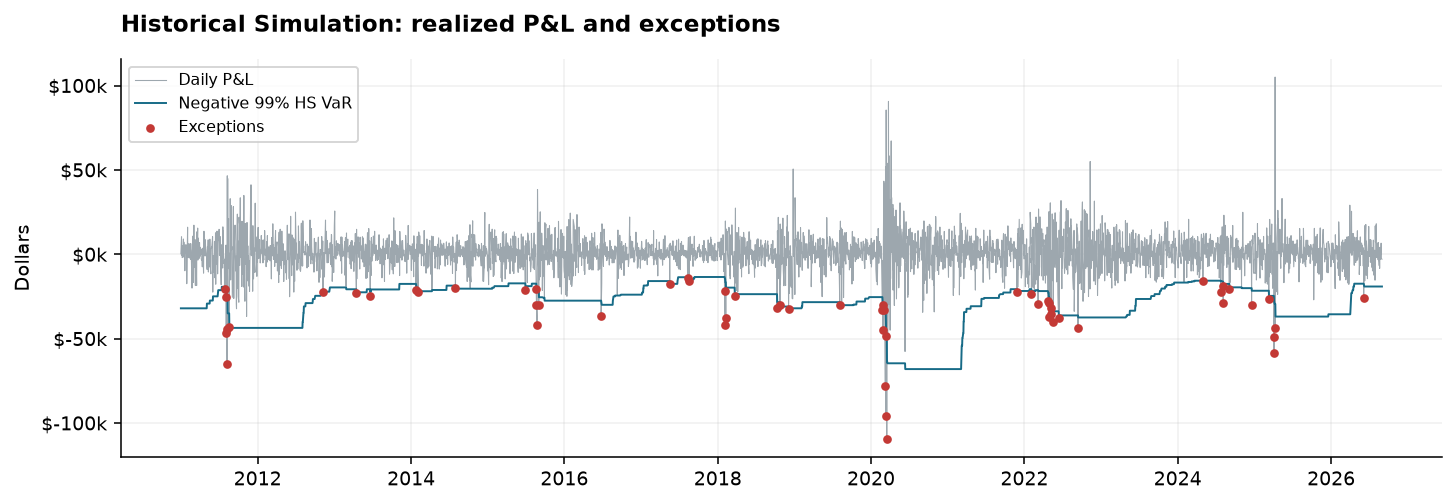

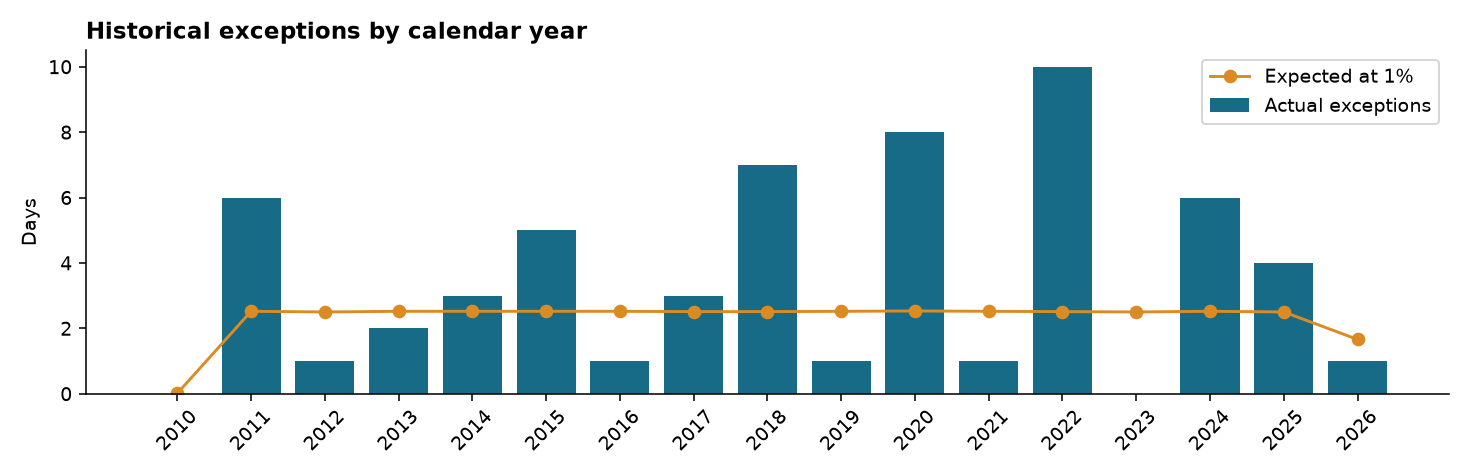

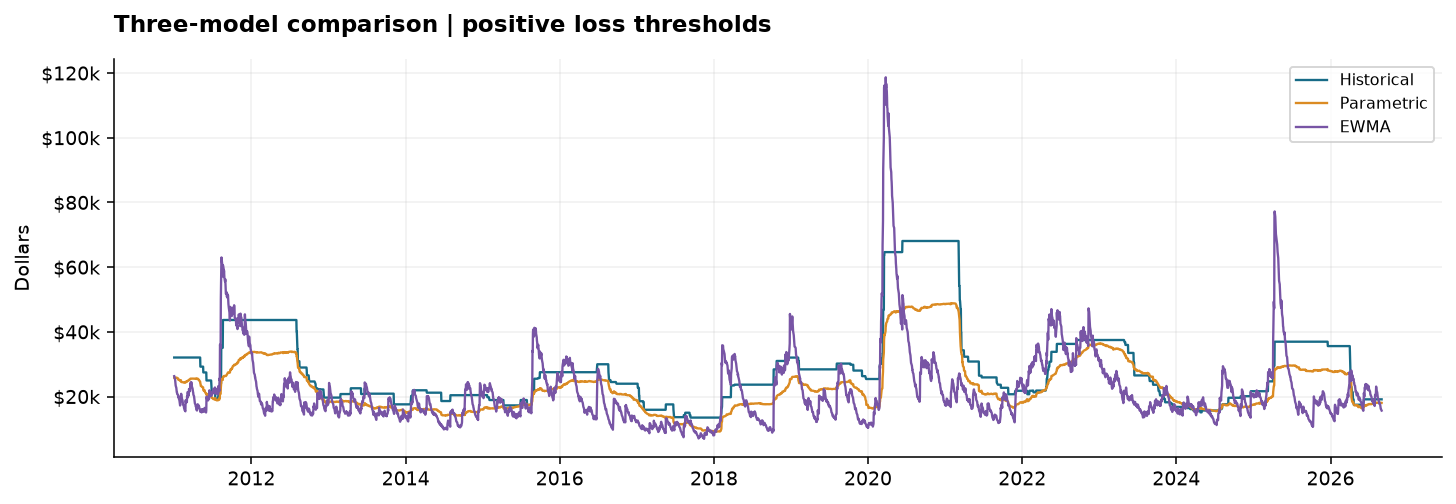

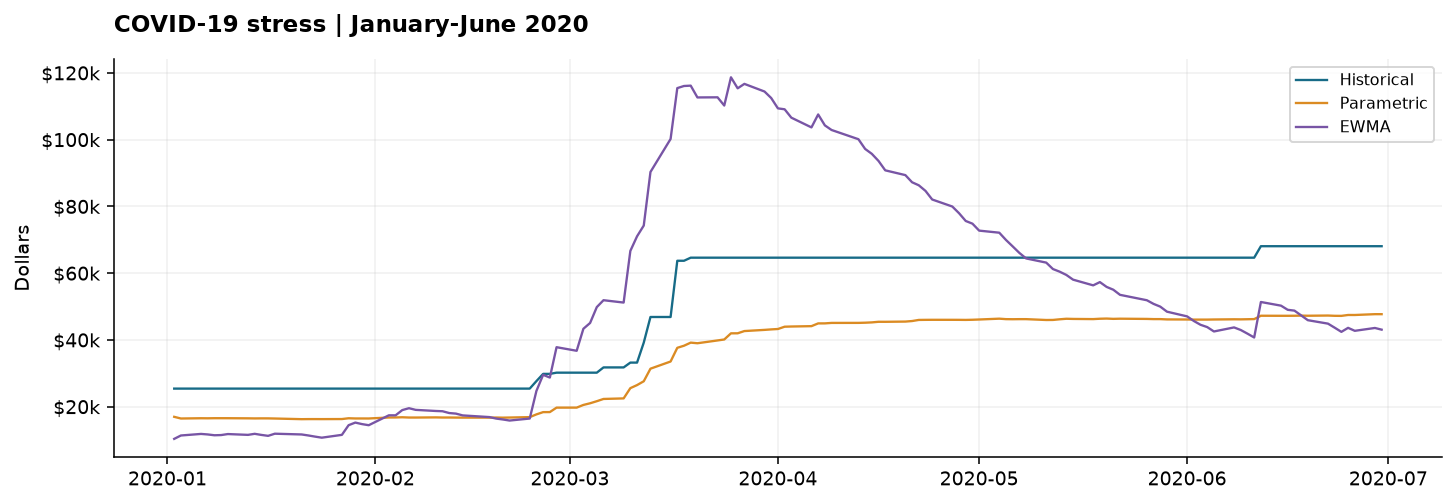

In [8]:
from IPython.display import display, Image
display(summary)
display(annual[annual.Model=='Historical'])
display(stress)
display(sensitivity)
for name in ['historical_exceptions.png','annual_exceptions.png','comparison_full.png','comparison_covid.png']:
    display(Image(filename=str(FIG/name)))

## References
- General Notes.pdf, pp. 22-31; team development documentation and pinned model files.
- [NumPy percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html)
- [Kupiec POF reference](https://www.mathworks.com/help/risk/varbacktest.pof.html)
- [Christoffersen independence reference](https://www.mathworks.com/help/risk/varbacktest.cci.html)

The analysis was independently calculated before cross-checking the team EWMA validation tables, which agree on all three baseline test statistics.